<a href="https://colab.research.google.com/github/lokesh200508/Machine-learning-ITA0603/blob/main/MACHINELEARNING_pynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

EXPERIMENT 1

In [ ]:
# Start with the most specific hypothesis
hypothesis = ['Ø', 'Ø', 'Ø', 'Ø']

# FIND-S algorithm using the defined 'data' DataFrame
for i in range(len(data)):

    # Check whether the example is positive
    if data.iloc[i]['Play'] == 'Yes':

        for j in range(4):

            if hypothesis[j] == 'Ø':
                hypothesis[j] = data.iloc[i, j]

            elif hypothesis[j] != data.iloc[i, j]:
                hypothesis[j] = '?'

print("Final Most Specific Hypothesis (FIND-S):")
print(hypothesis)

Final Most Specific Hypothesis (FIND-S):
['Sunny', 'Warm', '?', '?']


EXPERIMENT 2

CANDIDATE-ELIMINATION ALGORITHM

In [ ]:
import pandas as pd
import io

# Sample training data for PlayTennis (Candidate-Elimination Algorithm)
csv_data = """Sky,AirTemp,Humidity,Wind,Play
Sunny,Warm,Normal,Strong,Yes
Sunny,Warm,High,Strong,Yes
Rainy,Cold,High,Strong,No
Sunny,Warm,High,Light,Yes"""

try:
    # Try reading the uploaded file first
    data = pd.read_csv('/content/training_data.csv')
    print("Loaded data from file successfully.")
except FileNotFoundError:
    # Fallback to sample data if file is not present
    print("File '/content/training_data.csv' not found. Using fallback sample dataset.")
    data = pd.read_csv(io.StringIO(csv_data))

attributes = list(data.columns[:-1])
num_attributes = len(attributes)

# Initial boundaries
S = ['Ø'] * num_attributes
G = [['?'] * num_attributes]

# Check whether hypothesis covers example
def covers(hypothesis, example):
    for i in range(num_attributes):
        if hypothesis[i] != '?' and hypothesis[i] != example[i]:
            return False
    return True

# Candidate-Elimination Algorithm
for index, row in data.iterrows():
    example = list(row[:-1])
    target = row['Play']

    # Positive example
    if target == 'Yes':
        # Remove inconsistent hypotheses from G
        G = [g for g in G if covers(g, example)]

        # Generalize S
        for i in range(num_attributes):
            if S[i] == 'Ø':
                S[i] = example[i]
            elif S[i] != example[i]:
                S[i] = '?'

        # Remove from G any hypothesis that is not consistent with S
        G = [g for g in G if covers(g, S)]

    # Negative example
    else:
        # Specialize G to exclude the negative example
        temp_G = []
        for g in G:
            if covers(g, example):
                # Create specialized versions of g
                for i in range(num_attributes):
                    if g[i] == '?':
                        for val in data[attributes[i]].unique():
                            if val != example[i]:
                                g_special = g.copy()
                                g_special[i] = val
                                # Only keep if it is consistent with S
                                if covers(g_special, S):
                                    temp_G.append(g_special)
            else:
                temp_G.append(g)
        G = temp_G

# Remove duplicate and redundant hypotheses from G
G = [list(x) for x in set(tuple(x) for x in G)]

print("\nTraining Data:")
print(data)

print("\nSpecific Boundary (S):")
print(S)

print("\nGeneral Boundary (G):")
for g in G:
    print(g)

File '/content/training_data.csv' not found. Using fallback sample dataset.

Training Data:
     Sky AirTemp Humidity    Wind Play
0  Sunny    Warm   Normal  Strong  Yes
1  Sunny    Warm     High  Strong  Yes
2  Rainy    Cold     High  Strong   No
3  Sunny    Warm     High   Light  Yes

Specific Boundary (S):
['Sunny', 'Warm', '?', '?']

General Boundary (G):
['Sunny', '?', '?', '?']
['?', 'Warm', '?', '?']


EXPERIMENT 3 Decision Tree – ID3 Algorithm using Python

Original Dataset:
     Outlook Temperature Humidity    Wind PlayTennis
0      Sunny         Hot     High    Weak         No
1      Sunny         Hot     High  Strong         No
2   Overcast         Hot     High    Weak        Yes
3       Rain        Mild     High    Weak        Yes
4       Rain        Cool   Normal    Weak        Yes
5       Rain        Cool   Normal  Strong         No
6   Overcast        Cool   Normal  Strong        Yes
7      Sunny        Mild     High    Weak         No
8      Sunny        Cool   Normal    Weak        Yes
9       Rain        Mild   Normal    Weak        Yes
10     Sunny        Mild   Normal  Strong        Yes
11  Overcast        Mild     High  Strong        Yes
12  Overcast         Hot   Normal    Weak        Yes
13      Rain        Mild     High  Strong         No


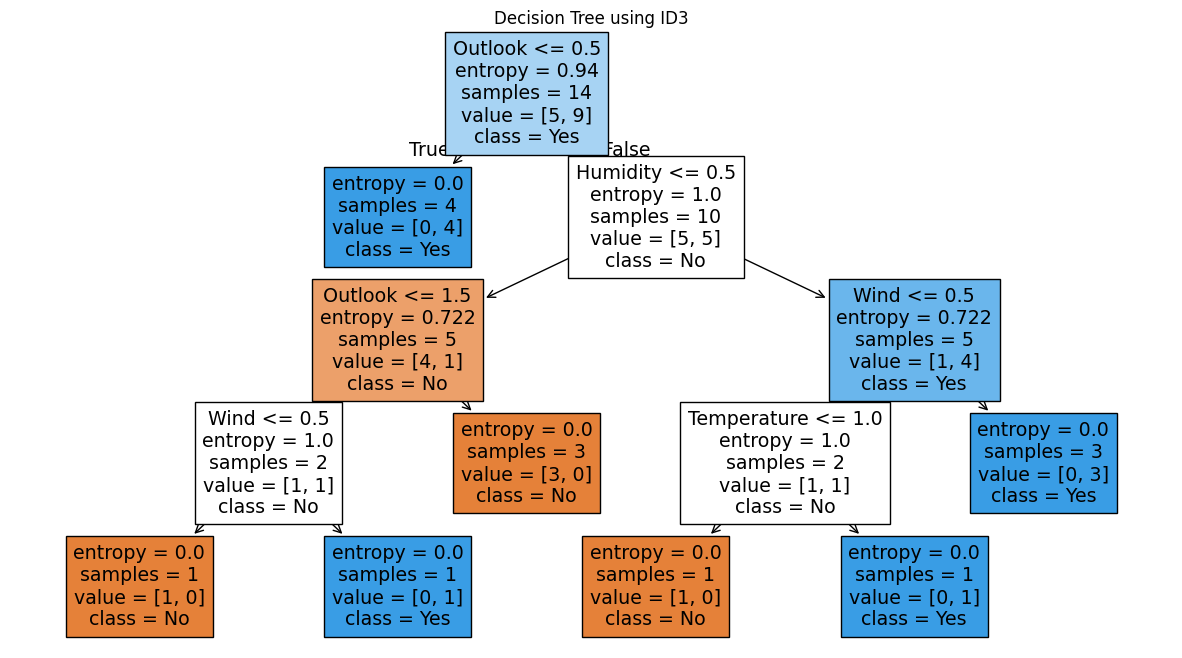


New Sample:
Outlook = Sunny
Temperature = Cool
Humidity = High
Wind = Strong

Prediction:
No, we should not play tennis.


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but OrdinalEncoder was fitted with feature names
  warnings.warn(


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import OrdinalEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree

# 1. Create dataset
data = {
    'Outlook': ['Sunny', 'Sunny', 'Overcast', 'Rain', 'Rain', 'Rain',
                'Overcast', 'Sunny', 'Sunny', 'Rain', 'Sunny', 'Overcast',
                'Overcast', 'Rain'],

    'Temperature': ['Hot', 'Hot', 'Hot', 'Mild', 'Cool', 'Cool',
                    'Cool', 'Mild', 'Cool', 'Mild', 'Mild', 'Mild',
                    'Hot', 'Mild'],

    'Humidity': ['High', 'High', 'High', 'High', 'Normal', 'Normal',
                 'Normal', 'High', 'Normal', 'Normal', 'Normal', 'High',
                 'Normal', 'High'],

    'Wind': ['Weak', 'Strong', 'Weak', 'Weak', 'Weak', 'Strong',
             'Strong', 'Weak', 'Weak', 'Weak', 'Strong', 'Strong',
             'Weak', 'Strong'],

    'PlayTennis': ['No', 'No', 'Yes', 'Yes', 'Yes', 'No',
                   'Yes', 'No', 'Yes', 'Yes', 'Yes', 'Yes',
                   'Yes', 'No']
}

df = pd.DataFrame(data)

print("Original Dataset:")
print(df)

# 2. Separate features and target
X = df[['Outlook', 'Temperature', 'Humidity', 'Wind']]
y = df['PlayTennis']

# 3. Encode categorical features
encoder = OrdinalEncoder()
X_encoded = encoder.fit_transform(X)

# 4. Create ID3 Decision Tree
model = DecisionTreeClassifier(
    criterion='entropy',
    random_state=0
)

# 5. Train the model
model.fit(X_encoded, y)

# 6. Display decision tree
plt.figure(figsize=(15, 8))

plot_tree(
    model,
    feature_names=X.columns,
    class_names=['No', 'Yes'],
    filled=True
)

plt.title("Decision Tree using ID3")
plt.show()

# 7. New sample
new_sample = [['Sunny', 'Cool', 'High', 'Strong']]

# 8. Encode new sample
new_sample_encoded = encoder.transform(new_sample)

# 9. Predict
prediction = model.predict(new_sample_encoded)

print("\nNew Sample:")
print("Outlook = Sunny")
print("Temperature = Cool")
print("Humidity = High")
print("Wind = Strong")

print("\nPrediction:")

if prediction[0] == 'Yes':
    print("Yes, we can play tennis.")
else:
    print("No, we should not play tennis.")

EXPERIMENT 4 ANN Using Backpropagation Algorithm

In [ ]:
import numpy as np
import pandas as pd

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, classification_report

# Load Iris dataset
iris = load_iris()

X = iris.data
y = iris.target

print("Dataset shape:", X.shape)
print("Classes:", iris.target_names)

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

# Normalize data
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Create Artificial Neural Network
model = MLPClassifier(
    hidden_layer_sizes=(10,),
    activation='relu',
    solver='adam',
    max_iter=1000,
    random_state=42
)

# Train using Backpropagation
model.fit(X_train, y_train)

print("\nANN training completed successfully.")

# Test the model
y_pred = model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("\nTest Accuracy:", accuracy)
print("Accuracy Percentage:", accuracy * 100, "%")

# Classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=iris.target_names
))

# Test a new sample
new_sample = [[5.1, 3.5, 1.4, 0.2]]

new_sample_scaled = scaler.transform(new_sample)

prediction = model.predict(new_sample_scaled)

print("New Sample:", new_sample)
print("Predicted Class:", iris.target_names[prediction[0]])

Dataset shape: (150, 4)
Classes: ['setosa' 'versicolor' 'virginica']

ANN training completed successfully.

Test Accuracy: 1.0
Accuracy Percentage: 100.0 %

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00         9
   virginica       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30

New Sample: [[5.1, 3.5, 1.4, 0.2]]
Predicted Class: setosa


EXPERIMENT 5: Implementation of K-Nearest Neighbours (K-NN) in Python

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

# Training data
X = [[1, 2], [2, 3], [3, 4], [6, 7], [7, 8]]
y = [0, 0, 0, 1, 1]

# Create K-NN model
model = KNeighborsClassifier(n_neighbors=3)

# Train the model
model.fit(X, y)

# Predict new data
result = model.predict([[4, 5]])

print("Predicted Class:", result[0])

Predicted Class: 0


EXPERIMENT 6: Implementation of Naïve Bayes Algorithm in Python Using Confusion Matrix and Accuracy

In [ ]:
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import confusion_matrix, accuracy_score
from sklearn.model_selection import train_test_split

# Input data
X = [[1, 2], [2, 3], [3, 4], [4, 5],
     [6, 7], [7, 8], [8, 9], [9, 10]]

# Output labels
y = [0, 0, 0, 0, 1, 1, 1, 1]

# Split the data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=1
)

# Create and train the model
model = GaussianNB()
model.fit(X_train, y_train)

# Predict the results
y_pred = model.predict(X_test)

# Display results
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("Accuracy:", accuracy_score(y_test, y_pred))

Confusion Matrix:
[[1 0]
 [0 1]]
Accuracy: 1.0


EXPERIMENT 7: Implementation of Logistic Regression (LR) Algorithm in Python

In [ ]:
from sklearn.linear_model import LogisticRegression

# Input data
X = [[1], [2], [3], [4], [5], [6]]
y = [0, 0, 0, 1, 1, 1]

# Create the model
model = LogisticRegression()

# Train the model
model.fit(X, y)

# Predict the result
result = model.predict([[4]])

print("Predicted Class:", result[0])

Predicted Class: 1


EXPERIMENT 8: Implementation of Linear Regression (LR) Algorithm in Python

In [ ]:
from sklearn.linear_model import LinearRegression

# Input data
X = [[1], [2], [3], [4], [5]]
y = [2, 4, 6, 8, 10]

# Create the model
model = LinearRegression()

# Train the model
model.fit(X, y)

# Predict the result
result = model.predict([[6]])

print("Predicted Value:", result[0])

Predicted Value: 12.0


EXPERIMENT 9: Comparison of Linear and Polynomial Regression Using Python

In [ ]:
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures

# Input and output data
X = np.array([[1], [2], [3], [4], [5]])
y = np.array([1, 4, 9, 16, 25])

# Linear Regression
lr = LinearRegression()
lr.fit(X, y)
print("Linear Prediction:", lr.predict([[6]])[0])

# Polynomial Regression
poly = PolynomialFeatures(degree=2)
X_poly = poly.fit_transform(X)

pr = LinearRegression()
pr.fit(X_poly, y)

new_data = poly.transform([[6]])
print("Polynomial Prediction:", pr.predict(new_data)[0])

Linear Prediction: 28.999999999999996
Polynomial Prediction: 36.00000000000002


EXPERIMENT10 : Implementation of Expectation-Maximization (EM) Algorithm in Python


In [ ]:
import numpy as np
from sklearn.mixture import GaussianMixture

# Input data
X = np.array([[1], [2], [3], [8], [9], [10]])

# Create EM model
model = GaussianMixture(n_components=2, random_state=0)

# Train the model using EM
model.fit(X)

# Predict clusters
result = model.predict(X)

print("Cluster Labels:", result)
print("Cluster Centers:", model.means_)

Cluster Labels: [1 1 1 0 0 0]
Cluster Centers: [[9.]
 [2.]]
